# modell-training

## Data Acquistion

### loading libs

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msn
%matplotlib inline
print('setup completed!')

setup completed!


### load - stoke excel

In [3]:
data = pd.read_excel('NEPSE_Trading_Reports/NEPSE_Continuous_MACD_Compounding_Results.xlsx')
data.head()

,Company,buy_date,buy_quantity,buy_rate,macd_on_buyDate,Total_amount_buyCost,sell_date,sell_quantity,sell_rate,macd_on_sellingDate,total_amount_recieved,profit/loss,profit/loss percentage respect to buy
0,NLIC,2015-01-05,10,4299.0,51.1810,43176.21,2015-03-04,10,4900.0,110.4363,48791.25,5615.04,13.00
1,NLIC,2015-01-06,10,4346.0,68.1232,43647.97,2015-03-04,10,4900.0,110.4363,48791.25,5143.28,11.78
2,NLIC,2015-01-07,10,4400.0,84.9283,44190.00,2015-03-04,10,4900.0,110.4363,48791.25,4601.25,10.41
3,NLIC,2015-01-08,10,4400.0,97.1269,44190.00,2015-03-04,10,4900.0,110.4363,48791.25,4601.25,10.41
4,CHCL,2015-03-12,10,1621.0,-11.0962,16295.79,2015-07-26,10,1700.0,33.7805,16911.25,615.46,3.78


### shape and size

In [4]:
data.shape

(475, 13)

### describe

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
buy_quantity,475.0,17.117895,9.683319,10.0000,10.0000,14.000,20.0000,49.0000
buy_rate,475.0,1610.308947,1839.240860,166.7000,470.0000,690.000,1735.4000,7171.0000
macd_on_buyDate,475.0,24.285217,77.600470,-232.5829,-1.7744,7.325,33.5570,1007.8918
Total_amount_buyCost,475.0,18878.042358,16870.735728,1698.2500,9721.2300,9907.920,17444.0800,72003.9100
sell_quantity,475.0,17.117895,9.683319,10.0000,10.0000,14.000,20.0000,49.0000
sell_rate,475.0,2071.663579,2214.953463,235.0000,658.5000,874.580,2444.0000,7624.0000
macd_on_sellingDate,475.0,87.219427,129.550753,-186.5477,14.6538,37.622,82.6387,955.4609
total_amount_recieved,475.0,25031.700968,21837.114000,2555.2900,10664.6800,13675.430,24787.6000,106310.7400
profit/loss,475.0,6153.658611,13298.472241,-345.5300,639.1650,1713.670,6182.0450,96940.8300
profit/loss percentage respect to buy,475.0,49.446695,132.804542,-1.2200,5.0050,13.070,28.8250,1034.6000


### info

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 475 entries, 0 to 474
Data columns (total 13 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Company                                475 non-null    str    
 1   buy_date                               475 non-null    str    
 2   buy_quantity                           475 non-null    int64  
 3   buy_rate                               475 non-null    float64
 4   macd_on_buyDate                        475 non-null    float64
 5   Total_amount_buyCost                   475 non-null    float64
 6   sell_date                              475 non-null    str    
 7   sell_quantity                          475 non-null    int64  
 8   sell_rate                              475 non-null    float64
 9   macd_on_sellingDate                    475 non-null    float64
 10  total_amount_recieved                  475 non-null    float64
 11  profit/loss      

### Null-values

In [7]:
data.isna().sum()

Company                                  0
buy_date                                 0
buy_quantity                             0
buy_rate                                 0
macd_on_buyDate                          0
Total_amount_buyCost                     0
sell_date                                0
sell_quantity                            0
sell_rate                                0
macd_on_sellingDate                      0
total_amount_recieved                    0
profit/loss                              0
profit/loss percentage respect to buy    0
dtype: int64

<Axes: >

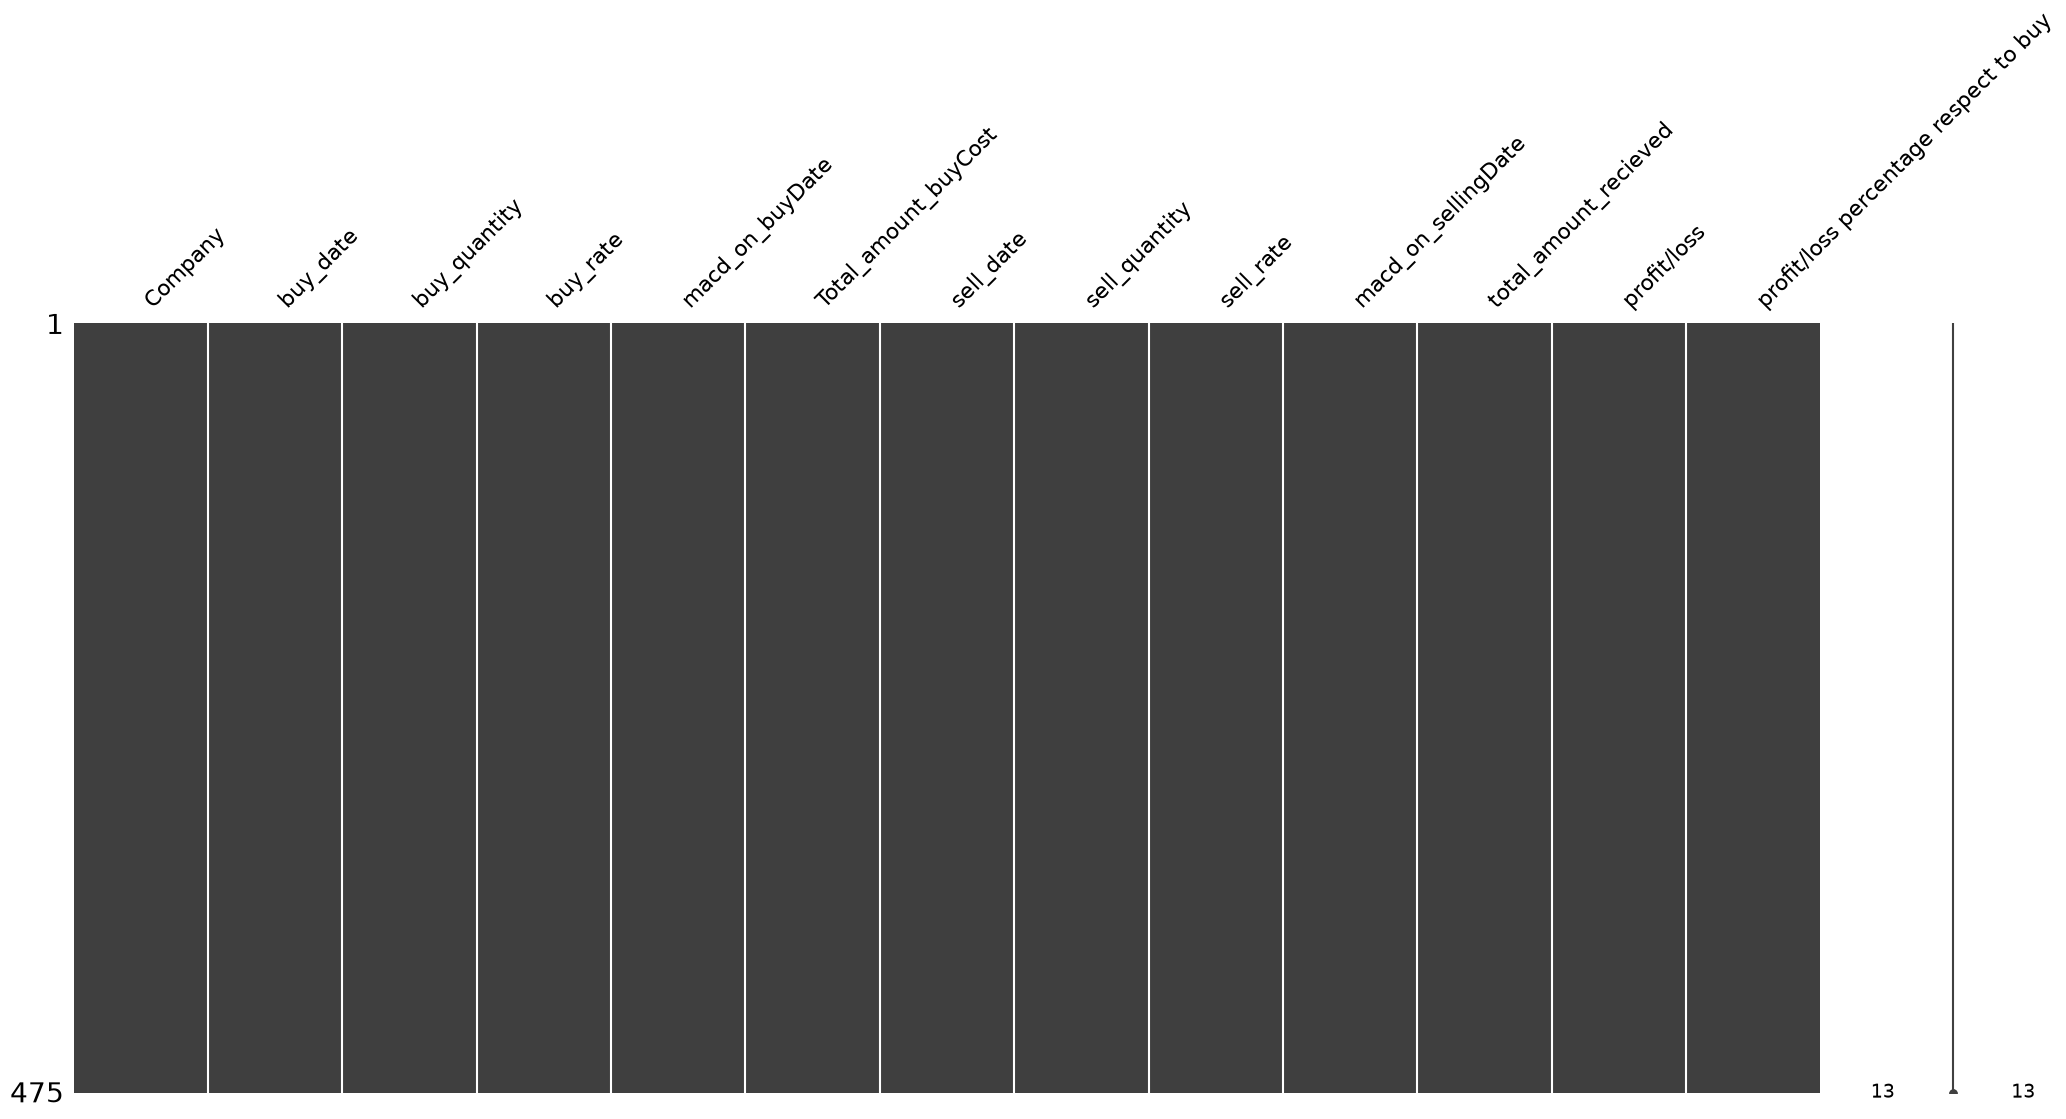

In [8]:
msn.matrix(data)

## Data filter

In [9]:
### Company data

In [10]:
data['Company'].value_counts()

Company
TPC      49
STC      47
NTC      47
HDL      30
SHPC     30
EBL      29
LICN     28
SCB      25
KBL      24
NFS      22
NLIC     20
CZBIL    20
BBC      20
AHPC     20
NABIL    17
CHCL     13
ADBL     13
GBIME    11
CIT       8
NIMB      2
Name: count, dtype: int64

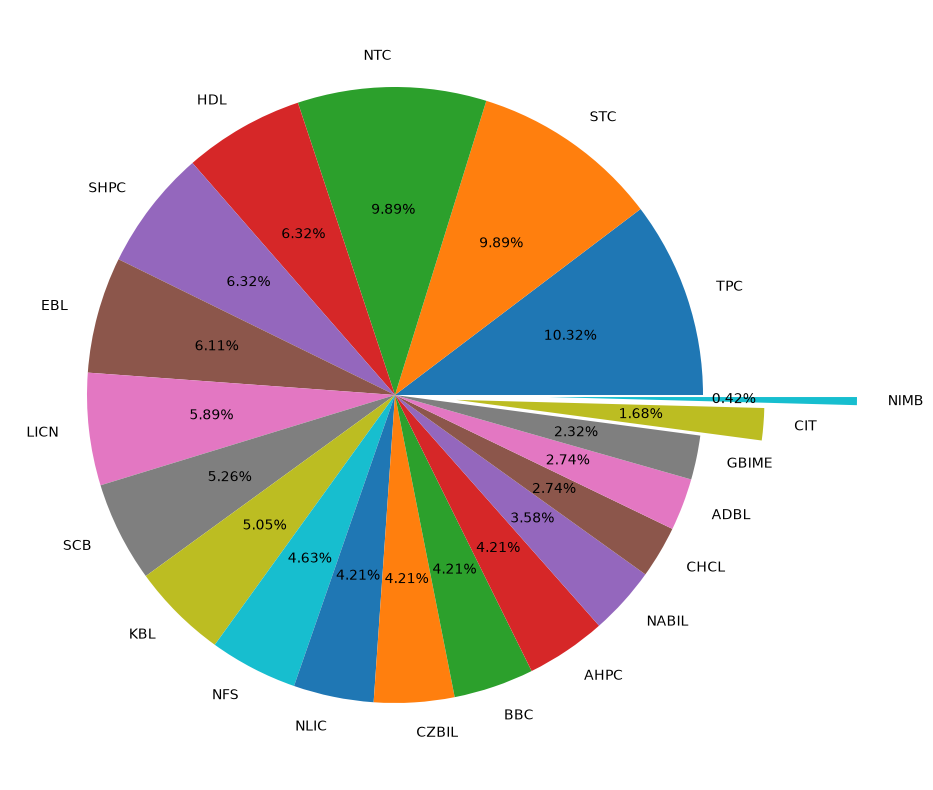

In [11]:
plt.figure(figsize=(10, 10))
counts = data['Company'].value_counts()
plt.pie(counts, autopct = '%1.2f%%', labels=counts.index, explode = [0,0,0,0,0,0,0,0,0,0,00,0,0,0,0,0,0,0,0.2,0.5])

### quantity counts

In [12]:
quantity = data.groupby('Company')['buy_quantity'].sum()

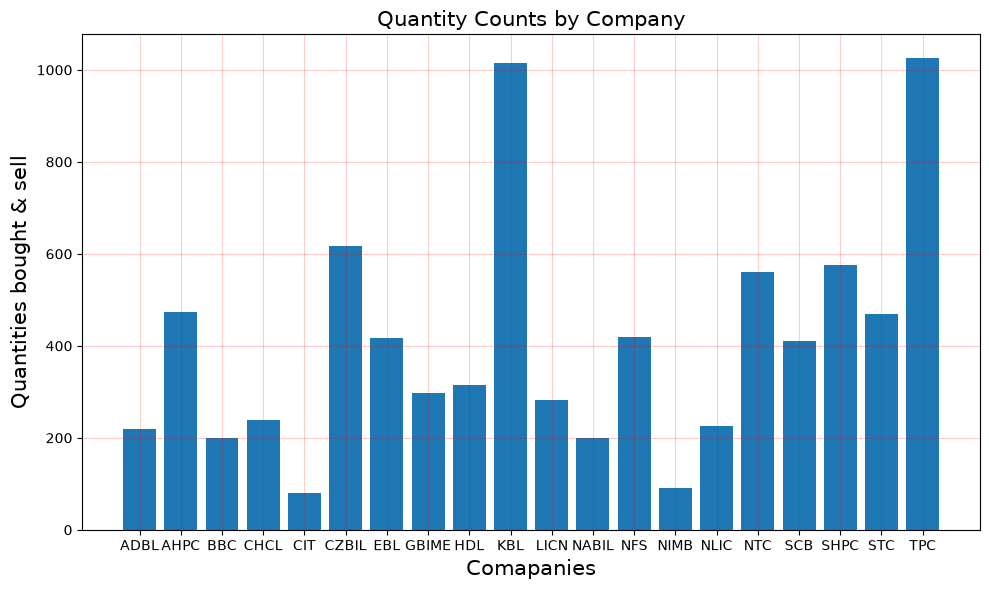

In [13]:
plt.figure(figsize=(10, 6))
plt.bar(x=quantity.index, height=quantity.values)
plt.title('Quantity Counts by Company', fontsize = 15)
plt.xlabel('Comapanies', fontsize = 15)
plt.ylabel('Quantities bought & sell', fontsize = 15)
plt.tight_layout()
plt.grid(c = 'r', alpha = 0.2)
plt.show()

### seperating dates

#### copy dataset

In [14]:
df = data.copy()

#### seperating buy dates 

In [15]:
#seperating buy dates
#converting buy date into datetime
df['buy_date'] = pd.to_datetime(df['buy_date'])
df['buy_year']  = df['buy_date'].dt.year
df['buy_month'] = df['buy_date'].dt.month
df['buy_day'] = df['buy_date'].dt.day
df['buy_weekdays'] = df['buy_date'].dt.dayofweek

In [16]:
df.head()

,Company,buy_date,buy_quantity,buy_rate,macd_on_buyDate,Total_amount_buyCost,sell_date,sell_quantity,sell_rate,macd_on_sellingDate,total_amount_recieved,profit/loss,profit/loss percentage respect to buy,buy_year,buy_month,buy_day,buy_weekdays
0,NLIC,2015-01-05,10,4299.0,51.1810,43176.21,2015-03-04,10,4900.0,110.4363,48791.25,5615.04,13.00,2015,1,5,0
1,NLIC,2015-01-06,10,4346.0,68.1232,43647.97,2015-03-04,10,4900.0,110.4363,48791.25,5143.28,11.78,2015,1,6,1
2,NLIC,2015-01-07,10,4400.0,84.9283,44190.00,2015-03-04,10,4900.0,110.4363,48791.25,4601.25,10.41,2015,1,7,2
3,NLIC,2015-01-08,10,4400.0,97.1269,44190.00,2015-03-04,10,4900.0,110.4363,48791.25,4601.25,10.41,2015,1,8,3
4,CHCL,2015-03-12,10,1621.0,-11.0962,16295.79,2015-07-26,10,1700.0,33.7805,16911.25,615.46,3.78,2015,3,12,3


#### seperating selling dates

In [17]:
df['sell_date'] = pd.to_datetime(df['sell_date'])
df['sell_year'] = df['sell_date'].dt.year
df['sell_month'] = df['sell_date'].dt.month
df['sell_day'] = df['sell_date'].dt.day
df['sell_date_weekday'] = df['sell_date'].dt.dayofweek



In [20]:
df.head()

,Company,buy_date,buy_quantity,buy_rate,macd_on_buyDate,Total_amount_buyCost,sell_date,sell_quantity,sell_rate,macd_on_sellingDate,...,profit/loss,profit/loss percentage respect to buy,buy_year,buy_month,buy_day,buy_weekdays,sell_year,sell_month,sell_day,sell_date_weekday
0,NLIC,2015-01-05,10,4299.0,51.1810,43176.21,2015-03-04,10,4900.0,110.4363,...,5615.04,13.00,2015,1,5,0,2015,3,4,2
1,NLIC,2015-01-06,10,4346.0,68.1232,43647.97,2015-03-04,10,4900.0,110.4363,...,5143.28,11.78,2015,1,6,1,2015,3,4,2
2,NLIC,2015-01-07,10,4400.0,84.9283,44190.00,2015-03-04,10,4900.0,110.4363,...,4601.25,10.41,2015,1,7,2,2015,3,4,2
3,NLIC,2015-01-08,10,4400.0,97.1269,44190.00,2015-03-04,10,4900.0,110.4363,...,4601.25,10.41,2015,1,8,3,2015,3,4,2
4,CHCL,2015-03-12,10,1621.0,-11.0962,16295.79,2015-07-26,10,1700.0,33.7805,...,615.46,3.78,2015,3,12,3,2015,7,26,6


#### drop buy_date and sell_date

In [21]:
df.drop(columns=['buy_date', 'sell_date'], inplace = True)

### best buy year

In [22]:
buy_year = df.groupby('buy_year')['buy_quantity'].sum()

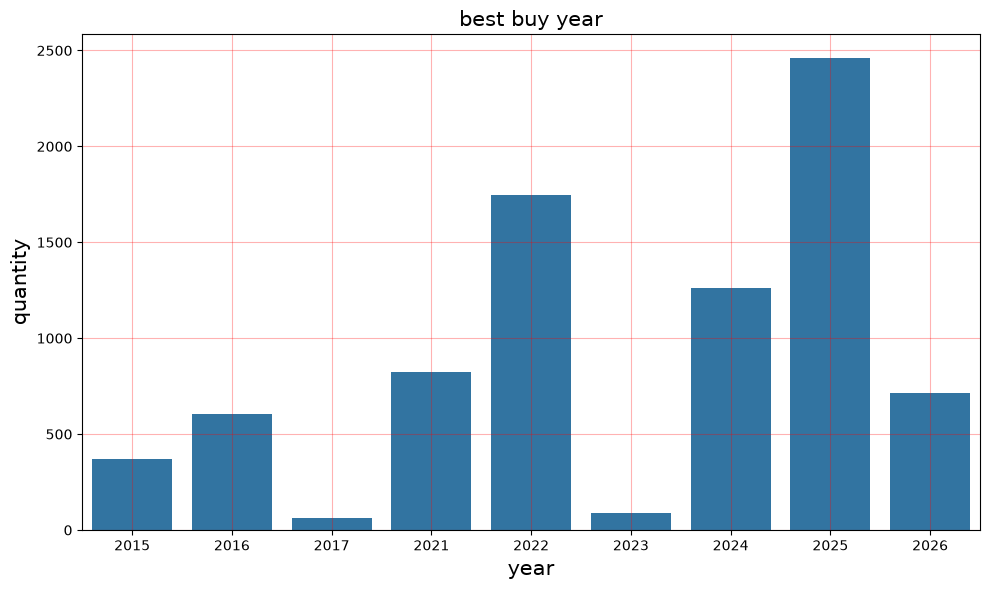

In [23]:
plt.figure(figsize=(10, 6))
sns.barplot(x = buy_year.index, y = buy_year.values)
plt.xlabel('year', fontsize = 15)
plt.ylabel('quantity', fontsize = 15)
plt.title('best buy year', fontsize = 15)
plt.grid(c ='r', alpha = 0.3)
plt.tight_layout()
plt.show()



### sell year

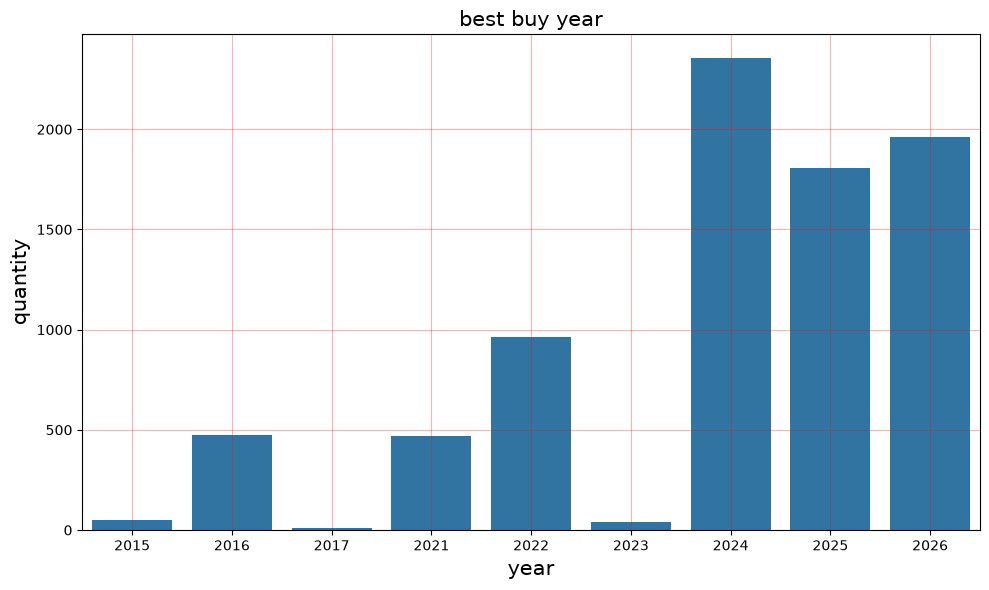

In [24]:
sell_year = df.groupby('sell_year')['sell_quantity'].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x = sell_year.index, y = sell_year.values)
plt.xlabel('year', fontsize = 15)
plt.ylabel('quantity', fontsize = 15)
plt.title('best buy year', fontsize = 15)
plt.grid(c ='r', alpha = 0.3)
plt.tight_layout()
plt.show()

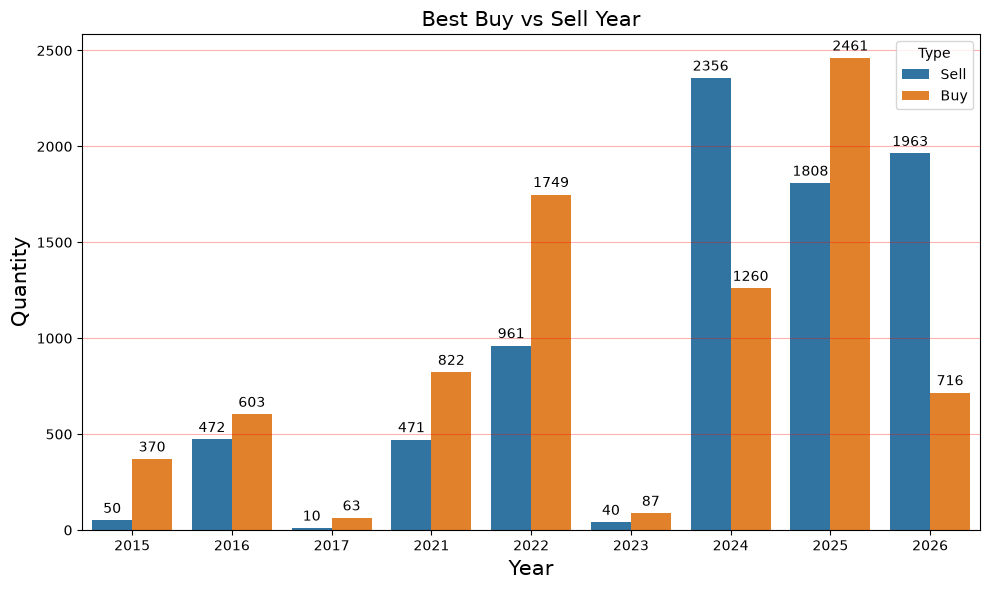

In [25]:
# 1. Combine sell_year and buy_year into a single tidy DataFrame for comparison
df_years = pd.DataFrame({
    'Sell': sell_year,
    'Buy': buy_year
}).reset_index().melt(id_vars='index', var_name='Type', value_name='Quantity')
# Rename 'index' to 'Year' depending on your index name
df_years.rename(columns={'index': 'Year'}, inplace=True)

# 2. Plot using Seaborn with 'hue' for side-by-side comparison
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_years, x='Year', y='Quantity', hue='Type')

# 3. Customizations
plt.xlabel('Year', fontsize=15)
plt.ylabel('Quantity', fontsize=15)
plt.title('Best Buy vs Sell Year', fontsize=15)
plt.grid(c='r', alpha=0.3, axis='y') # Grid usually looks cleaner applied only to y-axis for bar charts
plt.tight_layout()

# 4. Add labels to the bars safely
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)

plt.show()